In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, RFE
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    import holidays as pyholidays
    HAS_HOLIDAYS = True
except ImportError:
    HAS_HOLIDAYS = False

In [ ]:
processed_csv = Path("data/processed/household_power_consumption_tratado.csv")

df = pd.read_csv(
    processed_csv, 
    sep=";", 
    index_col="Datetime", 
    parse_dates=True, 
    low_memory=False
)

df_min = df.copy()
df_min["kwh_min"] = df_min["Global_active_power"] / 60.0

diario = pd.DataFrame(index=pd.date_range(df_min.index.normalize().min(),
                                        df_min.index.normalize().max(),
                                        freq="D"))
diario.index.name = "Data"

diario["consumo_kwh"] = df_min.groupby(df_min.index.normalize())["kwh_min"].sum()
diario["potencia_media_kw"] = df_min.groupby(df_min.index.normalize())["Global_active_power"].mean()
diario["potencia_max_kw"] = df_min.groupby(df_min.index.normalize())["Global_active_power"].max()
diario["potencia_std_kw"] = df_min.groupby(df_min.index.normalize())["Global_active_power"].std().fillna(0.0)
diario["tensao_media_v"] = df_min.groupby(df_min.index.normalize())["Voltage"].mean()
diario["sub1_kwh"] = df_min.groupby(df_min.index.normalize())["Sub_metering_1"].sum() / 1000.0
diario["sub2_kwh"] = df_min.groupby(df_min.index.normalize())["Sub_metering_2"].sum() / 1000.0
diario["sub3_kwh"] = df_min.groupby(df_min.index.normalize())["Sub_metering_3"].sum() / 1000.0

In [ ]:
X_feat = pd.DataFrame(index=diario.index)

X_feat["lag_1d_kwh"] = diario["consumo_kwh"].shift(0)  
X_feat["lag_2d_kwh"] = diario["consumo_kwh"].shift(1)   
X_feat["lag_7d_kwh"] = diario["consumo_kwh"].shift(6)   

X_feat["mm_3d_kwh"] = diario["consumo_kwh"].rolling(3, min_periods=1).mean()
X_feat["mm_7d_kwh"] = diario["consumo_kwh"].rolling(7, min_periods=1).mean()
X_feat["mm_14d_kwh"] = diario["consumo_kwh"].rolling(14, min_periods=1).mean()
X_feat["std_7d_kwh"] = diario["consumo_kwh"].rolling(7, min_periods=2).std().fillna(0.0)

X_feat["pot_max_t_kw"] = diario["potencia_max_kw"]
X_feat["pot_std_t_kw"] = diario["potencia_std_kw"]
X_feat["tensao_med_t_v"] = diario["tensao_media_v"]
X_feat["sub3_t_kwh"] = diario["sub3_kwh"]
X_feat["sub123_ratio_t"] = (
    (diario["sub1_kwh"] + diario["sub2_kwh"] + diario["sub3_kwh"])
    / diario["consumo_kwh"].replace(0, np.nan)
).fillna(0.0)

idx_alvo = diario.index + pd.Timedelta(days=1)
X_feat["alvo_dia_semana"] = idx_alvo.dayofweek
X_feat["alvo_fim_semana"] = (idx_alvo.dayofweek >= 5).astype(int)
X_feat["alvo_mes"] = idx_alvo.month

if HAS_HOLIDAYS:
    anos = sorted(set(idx_alvo.year))
    feriados_fr = pyholidays.France(years=anos)  
    X_feat["alvo_feriado"] = [int(d.date() in feriados_fr) for d in idx_alvo]
else:
    X_feat["alvo_feriado"] = 0

y_target = diario["consumo_kwh"].shift(-1)

dados_ml = pd.concat([X_feat, y_target.rename("y_prox_dia_kwh")], axis=1).dropna()
X = dados_ml[X_feat.columns].copy()
y = dados_ml["y_prox_dia_kwh"].copy()

print(f"Total de observações diárias válidas para treino/validação: {len(X)} | Nº de features: {X.shape[1]}")

Total de observações diárias válidas para treino/validação: 541 | Nº de features: 16


In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
k_sel = 8  

def avaliar_metricas(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return rmse, mae, r2

base_rmse, base_mae, base_r2 = [], [], []

full_rmse, full_mae, full_r2 = [], [], []

filter_rmse, filter_mae, filter_r2 = [], [], []
rfe_rmse, rfe_mae, rfe_r2 = [], [], []
lasso_rmse, lasso_mae, lasso_r2 = [], [], []

cont_filter = pd.Series(0, index=X.columns)
cont_rfe = pd.Series(0, index=X.columns)
cont_lasso = pd.Series(0, index=X.columns)

for fold, (tr_idx, va_idx) in enumerate(tscv.split(X), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]

    y_pred_base = X_va["lag_1d_kwh"].to_numpy()
    r, m, q = avaliar_metricas(y_va, y_pred_base)
    base_rmse.append(r); base_mae.append(m); base_r2.append(q)

    pipe_full = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ])
    pipe_full.fit(X_tr, y_tr)
    r, m, q = avaliar_metricas(y_va, pipe_full.predict(X_va))
    full_rmse.append(r); full_mae.append(m); full_r2.append(q)

    pipe_filter = Pipeline([
        ("scaler", StandardScaler()),
        ("sel", SelectKBest(score_func=f_regression, k=k_sel)),
        ("reg", LinearRegression())
    ])
    pipe_filter.fit(X_tr, y_tr)
    mask_f = pipe_filter.named_steps["sel"].get_support()
    cont_filter.loc[mask_f] += 1
    r, m, q = avaliar_metricas(y_va, pipe_filter.predict(X_va))
    filter_rmse.append(r); filter_mae.append(m); filter_r2.append(q)

    pipe_rfe = Pipeline([
        ("scaler", StandardScaler()),
        ("sel", RFE(estimator=LinearRegression(), n_features_to_select=k_sel, step=1)),
        ("reg", LinearRegression())
    ])
    pipe_rfe.fit(X_tr, y_tr)
    mask_r = pipe_rfe.named_steps["sel"].get_support()
    cont_rfe.loc[mask_r] += 1
    r, m, q = avaliar_metricas(y_va, pipe_rfe.predict(X_va))
    rfe_rmse.append(r); rfe_mae.append(m); rfe_r2.append(q)

    scaler_l = StandardScaler()
    X_tr_s = scaler_l.fit_transform(X_tr)
    X_va_s = scaler_l.transform(X_va)

    lasso_cv = LassoCV(cv=TimeSeriesSplit(n_splits=3), random_state=109095, max_iter=10000)
    lasso_cv.fit(X_tr_s, y_tr)
    coef_abs = np.abs(lasso_cv.coef_)
    mask_l = coef_abs > 1e-4
    
    if mask_l.sum() == 0:
        top_idx = np.argsort(coef_abs)[-k_sel:]
        mask_l = np.zeros(X.shape[1], dtype=bool)
        mask_l[top_idx] = True

    cont_lasso.loc[mask_l] += 1
    reg_lasso = LinearRegression()
    reg_lasso.fit(X_tr_s[:, mask_l], y_tr)
    r, m, q = avaliar_metricas(y_va, reg_lasso.predict(X_va_s[:, mask_l]))
    lasso_rmse.append(r); lasso_mae.append(m); lasso_r2.append(q)


=== DESEMPENHO MÉDIO NOS FOLDS (TimeSeriesSplit, 5 splits) ===


,RMSE médio (kWh),MAE médio (kWh),R² médio
Baseline (y_hat_{t+1} = y_t),8.4484,6.6212,-0.1227
Regressão Linear (Todas),7.0543,5.6187,0.2399
Filter (SelectKBest k=8) + RL,7.2712,5.7169,0.1896
Wrapper (RFE k=8) + RL,6.9432,5.5039,0.2509
Embedded (LassoCV) + RL,6.9452,5.5304,0.2589



=== ESTABILIDADE DE SELEÇÃO ENTRE FOLDS ===


,Filter (folds/5),RFE (folds/5),Lasso (folds/5),Total_selecoes
mm_3d_kwh,5,5,5,15
pot_max_t_kw,5,4,5,14
sub3_t_kwh,2,5,5,12
lag_1d_kwh,5,5,0,10
sub123_ratio_t,0,5,5,10
lag_2d_kwh,5,4,0,9
pot_std_t_kw,5,3,1,9
alvo_fim_semana,0,4,5,9
mm_7d_kwh,5,1,2,8
tensao_med_t_v,0,2,5,7


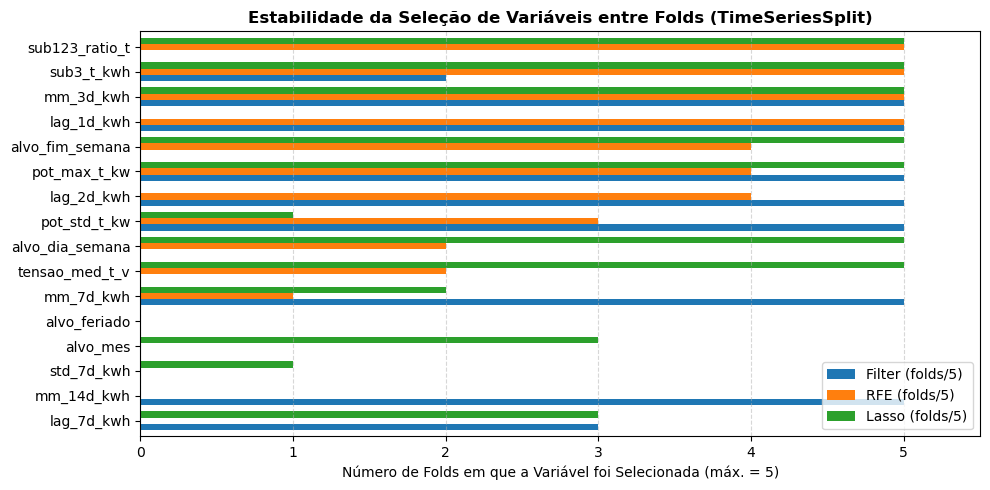

In [ ]:
resumo_modelos = pd.DataFrame({
    "RMSE médio (kWh)": [
        np.mean(base_rmse), np.mean(full_rmse),
        np.mean(filter_rmse), np.mean(rfe_rmse), np.mean(lasso_rmse)
    ],
    "MAE médio (kWh)": [
        np.mean(base_mae), np.mean(full_mae),
        np.mean(filter_mae), np.mean(rfe_mae), np.mean(lasso_mae)
    ],
    "R² médio": [
        np.mean(base_r2), np.mean(full_r2),
        np.mean(filter_r2), np.mean(rfe_r2), np.mean(lasso_r2)
    ]
}, index=[
    "Baseline (y_hat_{t+1} = y_t)",
    "Regressão Linear (Todas)",
    f"Filter (SelectKBest k={k_sel}) + RL",
    f"Wrapper (RFE k={k_sel}) + RL",
    "Embedded (LassoCV) + RL"
]).round(4)

print("\n=== DESEMPENHO MÉDIO NOS FOLDS (TimeSeriesSplit, 5 splits) ===")
display(resumo_modelos)

estabilidade = pd.DataFrame({
    "Filter (folds/5)": cont_filter,
    "RFE (folds/5)": cont_rfe,
    "Lasso (folds/5)": cont_lasso
})
estabilidade["Total_selecoes"] = estabilidade.sum(axis=1)
print("\n=== ESTABILIDADE DE SELEÇÃO ENTRE FOLDS ===")
display(estabilidade.sort_values("Total_selecoes", ascending=False))

fig, ax = plt.subplots(figsize=(10, 5))
est_plot = estabilidade.drop(columns=["Total_selecoes"]).sort_values(by="RFE (folds/5)", ascending=True)
est_plot.plot(kind="barh", ax=ax, width=0.75)
ax.set_title("Estabilidade da Seleção de Variáveis entre Folds (TimeSeriesSplit)", fontweight="bold")
ax.set_xlabel("Número de Folds em que a Variável foi Selecionada (máx. = 5)")
ax.set_xlim(0, 5.5)
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()